## **About this Notebook**

This notebook is the learning phase of the counting work. It follows a single dev clip `dev_overhead_medium_congest_01.mp4`, which is viewed from an overhead camera angle with medium/moderate traffic and a congested lane. It is worked on from the first counting run to an actual working setup, and it documents each step in detail: 

1. What we tried
2. What went wrong
3. Why each fix was added.

The write-ups here are longer than usual on purpose because this is where the counting mechanisms and conventions were worked out, which include:

- Config file content structure
- Counting line conventions
- Cooldown
- Region-gated counting
- Hysteresis and its confirmation thresholds

The sections build on each other, so read and run them from top to bottom. The remaining dev clips are covered in a separate notebook (`counting-tuning-on-dev-clips`). That one will move faster, only showing a results table per run and a short summary per clip, referring back here for how the mechanisms work.

## **0. Imports**

In [1]:
import pickle
import time
import yaml

import cv2
from matplotlib import pyplot as plt 
import matplotlib.patches as patches
from matplotlib.patches import Polygon 
import numpy as np
import pandas as pd
from PIL import Image

import ultralytics 
from ultralytics import YOLO

# %matplotlib widget

## **1. Where to Place the Counting Line**

The lines will be configured by hand for each clip since different clips vary in camera angle and road geometry so the line coordinates must adapt. Each line will be placed inside the clip's reliable detection zone, which is the region where detections and track IDs are most stable. We have identified this zone in our earlier notebook experiments. We have also noted that placing the line outside this reliable zone entails that vehicles will be counted in a spot where the tracker and detections are unreliable, which defeats the purpose of counting correctly. 

**A good line placement:**

- Crosses the road roughly perpendicular to the direction of travel
- Sits in the lower half of the frame where detections are strong and the tracker matches them efficiently
- Has space on both sides of the line so vehicles are not entering or leaving the frame right at the exact line
- Avoids spots where vehicles regularly stop or queue, such as near intersections or merge points where inching forward would repeatedly trigger the line.

## **2. Define the Line Config Format**

We will need to create a yaml config file that maps clip names to line coordinates. The format is:

```
  clip_name:

      incoming:
        coords: [[x1, y1], [x2, y2]]
        directions:
          negative: "A --> B"
          positive: "B --> A"
    
      outgoing:
        coords: [[x1, y1], [x2, y2]]
        directions:
          negative: "A --> B"
          positive: "B --> A"
```

To figure out whether a vehicle has crossed the line, we use something called the ***cross-product sign***.   
It is the sign of the value (positive or negative) resulting from the ***cross product of the line vector and the anchor point (a coordinate in a tracked detection)***. 

`cross_product_value = (x2 - x1) * (py - y1) - (y2 - y1) * (px - x1)`

The sign of this cross product tells us which side of the line the vehicle is on, positive on one side of the line and negative on the other. 

When that sign flips between frames, the vehicle will be counted as crossed. 

The `directions` field maps the two cross-product sign to a direction label (A --> B and B --> A).   
Which side of the line the labels A and B represent are arbitrary and what matters is that they distinguish the two sides of the line consistently for a given clip.   
When placing the line, we decide which physical direction (e.g., northbound) corresponds to A --> B or B --> A . 

## **3. Visualizing the Counting Line**

In [2]:
# Reused from the detection-per-frame-analysis notebook
def get_frame(frame_idx, vid_cap, fmt="RGB"):
    """For capturing a single frame specified by index"""
    vid_cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = vid_cap.read()

    if not ret: return
    if fmt == "RGB":
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame

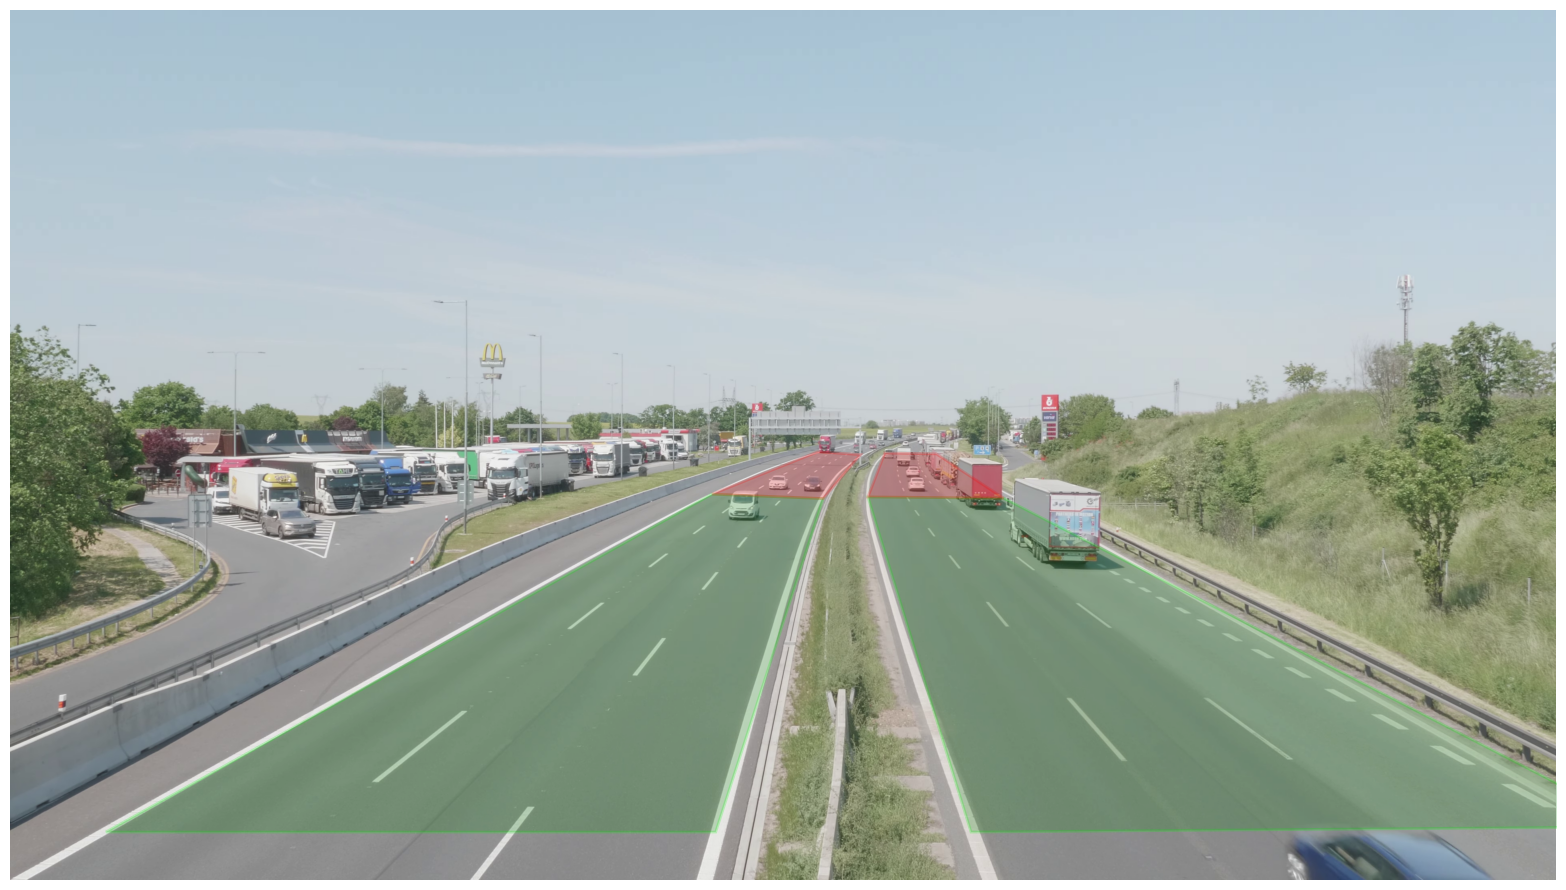

In [3]:
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
frame = get_frame(111, cap1)

fig1, ax1 = plt.subplots(1, figsize=(16, 9))
ax1.imshow(frame)

left_rdz_zpoints = [(238, 2041),  # bottom-left corner
                    (1743, 1202),  # top-left corner
                    (2019, 1213),  # top-right corner
                    (1752, 2041)] # bottom-right corner

left_farzone_zp = [(1743, 1202),  # bottom-left corner
                   (2005, 1097),  # top-left corner
                   (2112, 1104),  # top-right corner
                   (2019, 1213)]  # bottom-right corner

right_rdz_zpoints = [(2386, 2041),  # bottom-left corner
                    (2130, 1209),  # top-left corner
                    (2467, 1212),  # top-right corner
                    (4050, 2028)] # bottom-right corner

right_farzone_zp = [(2130, 1209),  # bottom-left corner
                   (2172, 1100),  # top-left corner
                   (2300, 1102),  # top-right corner
                   (2467, 1212)]  # bottom-right corner

left_rdz = Polygon(left_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

left_fz = Polygon(left_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

right_rdz = Polygon(right_rdz_zpoints, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

right_fz = Polygon(right_farzone_zp, closed=True, 
                   facecolor='red', alpha=0.2, 
                   edgecolor='red', linewidth=2)

ax1.add_patch(left_rdz), ax1.add_patch(left_fz)
ax1.add_patch(right_rdz), ax1.add_patch(right_fz)

h, w = frame.shape[:-1]
ax1.set_xlim(0, w)
ax1.set_ylim(h, 0) 
ax1.axis('off')
plt.tight_layout()
plt.show()

# Click 4 points, Each direction's counting line corresponds to two points
points = plt.ginput(4)
print(points)
print(frame.shape) 

In [4]:
print(type(fig1.canvas))

<class 'matplotlib.backends.backend_agg.FigureCanvasAgg'>


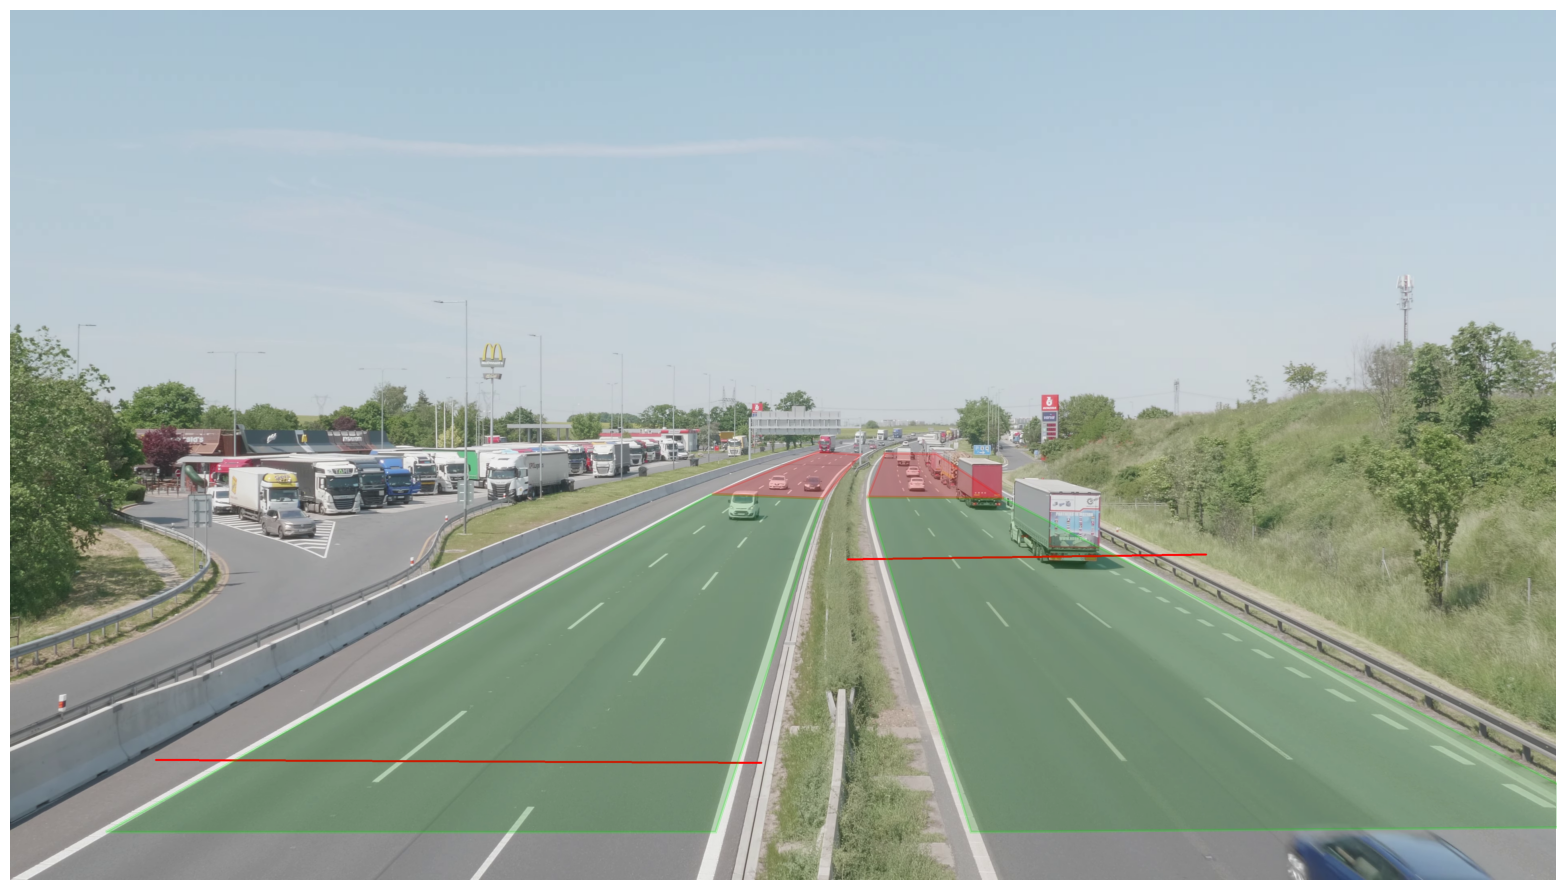

In [4]:
# Note that these coordinates are adjusted versions of the original
# coordinates captured in `points`, not the original values themselves.
pt1 = (362, 1862)
pt2 = (1866, 1869)
pt3 = (2080, 1364)
pt4 = (2970, 1352)

plt.figure(fig1)
cv2.line(frame, pt1, pt2, (255, 0, 0), 3)
cv2.line(frame, pt3, pt4, (255, 0, 0), 3)

plt.imshow(frame)
plt.show()

## **4. Notes on Counting Line Conventions**

The counting line is a line segment with a direction, which entails a start point and an end point. The direction of this vector determines which side is positive and which is negative.

For example, say our line goes from $(100, 400)$ to $(500, 420)$, left-to-right and roughly horizontal, slanting slightly downward. We use the cross-product formula:

$$cross\_product = (x2 - x1) * (py - y1) - (y2 - y1) * (px - x1)$$

- The vehicle detection anchor point is at $(300, 350)$, which is above the line:

$$
\begin{aligned}
side &= (500-100)(350-400) - (420-400)(300-100) \\
     &= 400(-50) - 20(200) \\
     &= -20000 - 4000 \\
     &= -24000
\end{aligned}
$$

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;The negative value is above the line crossing

- Vehicle anchor at $(300, 450)$, below the line:

$$
\begin{aligned}
side &= (500-100) * (450-400) - (420-400) * (300-100) \\
     &= 400 * 50 - 20 * 200 \\
     &= 20000 - 4000  \\
     &= 16000 \\
\end{aligned}
$$

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;The positive value is below the line crossing

If that vehicle moved from $(300, 350)$ to $(300, 450)$ across frames, the sign will change from negative to positive. That is a crossing, and the new side is positive.

**Our convention:** the line vector always goes left to right (start point on the left, end point on the right), regardless of the line’s angle. This keeps the sign interpretation consistent across all clips. For a left-to-right line in image coordinates (where y increases downward), the positive side is below the line and the negative side is above it. The positive side is always associated with `A` and negative side with `B`. So if the crossing happens from postive to negative, then direction will be `A --> B`. Conversely, if the crossing goes from negative (B) to positive (A), the direction is `B --> A`. For instance, since A (positive) is below the line, an `A --> B` direction means the anchor point advances from below to above the line for an overhead camera angle. `B --> A` means the anchor point advances from above (negative) to below (positive) the line. 

**Notes:**

- Reversing the line vector direction (making it right to left) flips the signs. For a roughly horizontal line, positive cross-products will now be above the line while negatives will be below, even though the geometry does not change (only the labeling does).
  
- Standard for line crossing mechanics varies in the industry and there isn't seem to be a universal one. For instance, computer vision solutions like Axelera SDK, Slighthound, and Google Cloud Vision AI approaches the mechanics of line crossings differently.

- The resulting sign from a cross-product is consistent for a given line direction. In our case, the line is left to right in direction, so positive below, negative above for overhead horizontal lines. For roadside angle views, the same line direction will be applied (left to right).

- By default, what each sign means (which physical traffic direction it represents) for us is `direction_labels = {negative: "A --> B"`, `positive: "B --> A}"`. This will be configured via the `directions` field in `config/counting_lines.yaml`.

- Our keys (`positive` and `negative`) represent the new side where the vehicle arrived, not the old side. For instance, `direction_labels["positive"]` --> `B --> A` means that after the crossing, the anchor point ended up on the positive side.

## **5. First Counting Run**

In [6]:
# from src/tracking.py. Outputs a List[Dict] of tracked detections
def track_vehicles(frame, model, agnos_nms=True, track_file="bytetrack.yaml"):

    results = model.track(frame, 
                          classes=[2,3,5,7],
                          conf=0.25,
                          agnostic_nms=agnos_nms,
                          verbose=False,
                          persist=True, 
                          tracker=track_file)

    track_ids = results[0].boxes.id

    if track_ids is None:
        return []

    boxes = results[0].boxes.xyxy
    conf_scores = results[0].boxes.conf
    cls_ids = results[0].boxes.cls

    tracked_detections = []
    for box, score, cls_id, tr_id in zip(boxes, conf_scores, cls_ids, track_ids):

        prediction = {"box": box.tolist(),
                      "conf_score": score.item(),
                      "cls_id": cls_id.item(),
                      "track_id": tr_id.item()}

        tracked_detections.append(prediction)
    
    return tracked_detections

In [7]:
# from src/counting/py. for counting tracked detections and recording 
# a track's last side (based on cross-product sign)
class LineCrossingCounter:

    def __init__(self, source, fps, line_id, line, dir_labels, cooldown=30):
        self.source = source
        self.fps = fps
        self.line_id = line_id
        self.line = line
        self.dir_labels = dir_labels
        self.cooldown = cooldown
        self.last_crossed = {}
        self.track_sides = {}

        self.counts = {self.dir_labels["positive"]:0, 
                       self.dir_labels["negative"]:0}

        self.events = []

    def update(self, tracked_detections, frame_number):

        for detection in tracked_detections:

            box = detection["box"]
            x1, x2 = self.line[0][0], self.line[1][0]
            y1, y2 = self.line[0][1], self.line[1][1]
            x_anchor = (box[0] + box[2]) /2
            y_anchor = box[3]
            cross_product = (x2 - x1) * (y_anchor - y1) - (y2 - y1) * (x_anchor - x1)

            sign = "positive" if cross_product > 0 else "negative"
            track_id = detection["track_id"]

            if track_id in self.track_sides:
                if self.track_sides[track_id] != sign:

                    if track_id in self.last_crossed:
                        num_frames = frame_number - self.last_crossed[track_id]

                        if num_frames <= self.cooldown:
                            continue

                    self.last_crossed[track_id] = frame_number
                    self.counts[self.dir_labels[sign]] += 1

                    # Build the event log and append to the event list
                    event = {
                        "source_video": self.source,
                        "line_id": self.line_id,
                        "vehicle_id": track_id,
                        "frame_number": frame_number,
                        "timestamp": frame_number / self.fps,
                        "direction": self.dir_labels[sign],
                        "class": CLASS_MAP[detection["cls_id"]],
                    }

                    self.events.append(event)

            self.track_sides[track_id] = sign        

In [8]:
CLASS_MAP = {2:"car", 3:"motorcycle", 5:"bus", 7:"truck"}

BOX_COLORS = {
    2: (255, 255, 255),  # car - white
    3: (255, 200, 100),  # motorcycle - light blue
    5: (203, 192, 255),  # bus - pink
    7: (0, 255, 255),    # truck - yellow
}

track_file = "../config/bytetrack_w_buffer60.yaml"


# Taken from tracking-video-analysis notebook
# modified to utilize new src code and accomodate counting 
def process_clip(cap, model, fname, counters):
    w,h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
                       
    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total_frames}")   

    start = time.time() 
    frame_ctr = 0

    # Count the total unique IDs that appeared across all frames
    unique_ids = set()   

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Generate a list of detections with tracks
        tracked_detections = track_vehicles(frame, 
                                            model, 
                                            agnos_nms=True, 
                                            track_file=track_file)

        # Draw the counting lines after detection and tracking
        # So it does not become part of what the model sees
        lines = [counter.line for counter in counters]
        for line in lines:
            cv2.line(frame, line[0], line[1], (0, 0, 255), 3)

        # Capture unique IDs
        unique_ids.update([d["track_id"] for d in tracked_detections])

        # Update counter states for all LineCrossingCounter objects
        for counter in counters:
            counter.update(tracked_detections, frame_ctr)

        # Draw the detected boxes with ID, class, and the current sign
        for d in tracked_detections:
            x1, y1, x2, y2 = [int(v) for v in d["box"]]
            track_id = d["track_id"]
            cls_id = int(d["cls_id"])
            color = BOX_COLORS[cls_id]
        
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 6)
        
            signs_lst = [f"{'in' if counter.line_id == 'incoming' else 'out'}:"
                         f"{ {'positive': '+', 'negative': '-'}.get(counter.track_sides.get(track_id), 'N/A') }"
                         for counter in counters]
            signs_str = ", ".join(signs_lst)
        
            label = (f"ID:{int(track_id)}, "
                     f"{CLASS_MAP[cls_id]}, "
                     f"{signs_str}")

             # th does not include baseline
            (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
            top = max(y1 - baseline - th - 8, 0)
        
            cv2.rectangle(frame, (x1, top), (x1 + tw + 8, top + th + baseline + 8), color, -1)
            cv2.putText(frame, label, 
                        (x1 + 4, top + th + 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

        # Draw the counting overlay to show counts for each line
        for row, counter in enumerate(counters):
            total_count = sum(counter.counts.values())
            txt_total = f"{counter.line_id} total: {total_count}"
            positive_lbl = counter.dir_labels['positive']
            negative_lbl = counter.dir_labels['negative']
            txt_positive = f"positive: {counter.counts[positive_lbl]}"
            txt_negative = f"negative: {counter.counts[negative_lbl]}" 
            cv2.putText(frame, 
                        txt_total + ", " + txt_positive + ", " + txt_negative,
                        (40, 120 + row * 50), 
                        cv2.FONT_HERSHEY_SIMPLEX, 
                        1.2, (255, 0, 0), 2)
        
        # No need to convert to BGR since frame 
        # remained BGR throughout the sequence
        out.write(frame)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

In [9]:
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")

with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f)

clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
dir_labels = incoming["directions"]  # Similar for both incoming and outgoing
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]

source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))
counter1 = LineCrossingCounter(source, fps, "incoming", in_coords, dir_labels)
counter2 = LineCrossingCounter(source, fps, "outgoing", out_coords, dir_labels)
counters = (counter1, counter2)

output_fname = "../outputs/output_count_dev_overhead_medium_congest_01.mp4"
process_clip(cap1, model, output_fname, counters)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 737ms
Prepared 1 package in 218ms
Installed 1 package in 2ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 288.5s
FPS: 10.0


In [10]:
counter1.events[4:7]

[{'source_video': 'dev_overhead_medium_congest_01.mp4',
  'line_id': 'incoming',
  'vehicle_id': 9.0,
  'frame_number': 60,
  'timestamp': 2.5,
  'direction': 'B --> A',
  'class': 'car'},
 {'source_video': 'dev_overhead_medium_congest_01.mp4',
  'line_id': 'incoming',
  'vehicle_id': 59.0,
  'frame_number': 120,
  'timestamp': 5.0,
  'direction': 'A --> B',
  'class': 'car'},
 {'source_video': 'dev_overhead_medium_congest_01.mp4',
  'line_id': 'incoming',
  'vehicle_id': 60.0,
  'frame_number': 122,
  'timestamp': 5.083333333333333,
  'direction': 'A --> B',
  'class': 'car'}]

**Observations:**

**Note:** The annotated output clip produced in this run is available [here](https://youtu.be/8qEdovo-e4o).   
Results referenced in the observations below are from this specific clip.   
Running the same code may produce slightly different results due to differences in hardware.

- The counting logic works as intended. We see crossings are recorded when a track’s anchor point changes side of a counting line
- The events also show the crossing's expected frame numbers, timestamps, and other information.
- However, we still cannot rely on this counting run's integrity due **cross-lane contamination**.
- It turns out, an anchor point also changes sign and registers as a crossing not just for its lane's line but for the other line as well.
- For example, an incoming vehicle also crosses the outgoing lane’s line, which flips its sign relative to that line and registers a second but false count.
- **The result:** an anchor point will trigger a count on both lines regardless of which lane it travels.
- This shows that cross-products do not have a notion of lane membership, so the counting line alone can’t separate lanes.
- **Planned fix:** We need to add a per-lane region of interest, which is a multi-point polygon covering the entire lane.
- This region of interest covers not just the reliable detection zone but the whole lane (RDZ + far zone).
- The ROI will ensure that no cross-products between anchor points and the other lane’s counting line are computed, so no false crossings can be recorded

## **6. Counting Run with Region-Gated Counting (ROI Filtering)**

We first visualize how the region of interest will appear for each for each counting line in the `dev_overhead_medium_congest_01.mp4` clip.

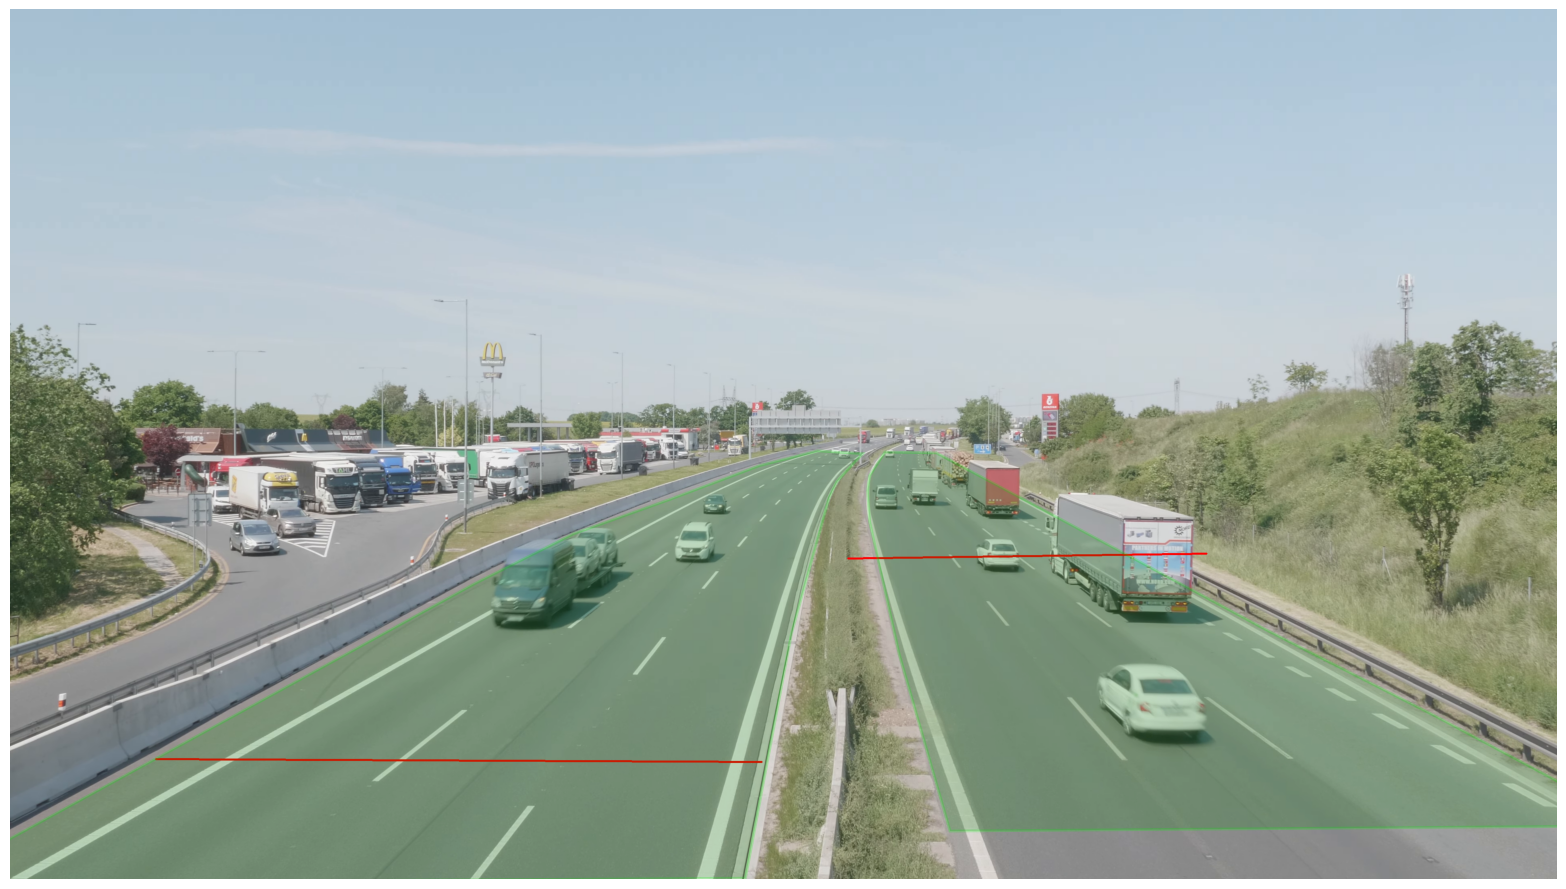

In [11]:
# Reuse from the detection-per-frame-analysis notebook
def get_frame(frame_idx, vid_cap, fmt="RGB"):
    """For capturing a single frame specified by index"""
    vid_cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = vid_cap.read()

    if not ret: return
    if fmt == "RGB":
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame


cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
frame = get_frame(2, cap1)

cv2.line(frame, pt1, pt2, (255, 0, 0), 3)
cv2.line(frame, pt3, pt4, (255, 0, 0), 3)

fig2, ax2 = plt.subplots(1, figsize=(16, 9))
ax2.imshow(frame)

left_roi_points = [(-200, 2170),    # bottom-left (lower bound)
                   (1155, 1426),  # left edge (first bend)
                   (1399, 1303),  # left edge (2nd bend)
                   (1640, 1217),  # left edge (3rd bend)
                   (1860, 1134),  # left edge (4th)
                   (2005, 1097),  # top-left (upper bound)
                   (2117, 1104),  # top-right (upper bound)
                   (2053, 1174),  # right edge bend 3
                   (2034, 1213),  # right edge bend 2
                   (1940, 1552),  # right edge bend 1
                   (1826, 2158)]  # bottom-right (lower bound)

right_roi_points = [(2334, 2041),  # bottom-left (lower bound)
                    (2208, 1603),  # left bend
                    (2134, 1272),  # left bend
                    (2129, 1196),  # left bend
                    (2134, 1159),  # left bend
                    (2172, 1100),  # top-left (upper bound)
                    (2300, 1102),  # top-right (upper bound)
                    (2585, 1254),  # right edge bend
                    (3120, 1542),  # right edge bend
                    (3536, 1754),  # right edge bend
                    (4050, 2028)]  # bottom-right (lower bound)

left_roi = Polygon(left_roi_points, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

right_roi = Polygon(right_roi_points, closed=True, 
                   facecolor='green', alpha=0.2, 
                   edgecolor='lime', linewidth=2)

ax2.add_patch(left_roi), ax2.add_patch(right_roi)

h, w = frame.shape[:-1]
ax2.set_xlim(0, w)
ax2.set_ylim(h, 0) 
ax2.axis('off')
plt.tight_layout()
plt.show()

In [12]:
def in_roi(roi, anchor_point):
    """Return True if anchor_point lies inside or on the edge of the polygon roi."""
    polygon = np.array(roi, dtype=np.int32)
    return cv2.pointPolygonTest(polygon, anchor_point, False) >= 0

# Update LineCrossingCounter to accomodate ROI checking
class LineCrossingCounter:

    def __init__(self, source, fps, line_id, line, roi, dir_labels, cooldown=30):
        self.source = source
        self.fps = fps
        self.line_id = line_id
        self.line = line
        self.roi = roi
        self.dir_labels = dir_labels
        self.cooldown = cooldown
        self.last_crossed = {}
        self.track_sides = {}

        self.counts = {self.dir_labels["positive"]:0, 
                       self.dir_labels["negative"]:0}

        self.events = []

    def update(self, tracked_detections, frame_number):

        for detection in tracked_detections:

            box = detection["box"]
            x_anchor = (box[0] + box[2]) /2
            y_anchor = box[3]

            # Check first if the anchor point lies within the roi or along its edges
            # If it does, proceed with the rest of the sequence, else skip the 
            # anchor point entirely from being recorded and counted relative to this line
            if not in_roi(self.roi, (x_anchor, y_anchor)):
                continue

            x1, x2 = self.line[0][0], self.line[1][0]
            y1, y2 = self.line[0][1], self.line[1][1]
            cross_product = (x2 - x1) * (y_anchor - y1) - (y2 - y1) * (x_anchor - x1)

            sign = "positive" if cross_product > 0 else "negative"
            track_id = detection["track_id"]

            if track_id in self.track_sides:
                if self.track_sides[track_id] != sign:

                    if track_id in self.last_crossed:
                        num_frames = frame_number - self.last_crossed[track_id]

                        if num_frames <= self.cooldown:
                            continue

                    self.last_crossed[track_id] = frame_number
                    self.counts[self.dir_labels[sign]] += 1

                    # Build the event log and append to the event list
                    event = {
                        "source_video": self.source,
                        "line_id": self.line_id,
                        "vehicle_id": track_id, 
                        "frame_number": frame_number,
                        "timestamp": frame_number / self.fps,
                        "direction": self.dir_labels[sign],
                        "class": CLASS_MAP[detection["cls_id"]],
                    }

                    self.events.append(event)

            self.track_sides[track_id] = sign        

In [13]:
model.predictor = None
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")

with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f)

clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
dir_labels = incoming["directions"]  # Similar for both incoming and outgoing
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]

source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))

roi_incoming = left_roi_points
roi_outgoing = right_roi_points

counter1 = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels)
counter2 = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels)
counters = (counter1, counter2)

output_path = "../outputs/output_count_dev_overhead_medium_congest_01_region_gated.mp4"
process_clip(cap1, model, output_path, counters) 

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 278.6s
FPS: 10.3


### **Observations**

**Note:** The annotated output clip produced in this run is available [here](https://youtu.be/m9ylX7UX5Vg).   
Results referenced in the observations below are from this specific clip.   
Running the same code may produce slightly different results due to differences in hardware.

**INCOMING LANE:**
- We count by hand 81 vehicle crossings. The system counted 83 (net +2, approx. 2.5%)
- The extra counts come from an articulated van with a trailer carrying two cars, which produced two boxes (seen at 0:00:00 - 01 start of the clip)
- This lane has no congestion with moderate traffic so this is the easier case

**OUTGOING LANE:**
- 71 crossings by hand, 72 by the system. We encountered three errors that caused the +1 mismatch:
  1. Starting at 0:01:22, a passing truck (with ID 1084) occluded a stationary one (ID 928) on the congested lane, shrinking its box and forcing it to cross early.  
     The stationary truck's box disappeared completely afterwards, only to reappear retaining its original ID, but its anchor point is now below the line.  
     Upon passing naturally, the track was counted once more (way past `cooldown=30`), resulting in a **double count**
  2. When the truck (ID 928) reappeared after the occlusion, with cooldown > 30, it appeared below the line, which triggered a positive B --> A count.
  3. The detector also missed one motorcycle at around 0:00:23.
- Passing cars did not disrupt stationary truck detections.
- Passing large trucks did disrupt stationary trucks. Their boxes shrank or disappeared while occluded and then returned.
- These disruptions happened several times, but only one produced a double count and a wrong-direction event at the same time.

## **7. Applying False-Crossing Suppression**

Since that occluded truck with ID 928 became a problem in the previous run (causing a double count and a wrong way error), it’s worth taking seriously. As observed, our counter trusts every sign flip as a real crossing. For a clean, stable detection, this rarely becomes an issue, but for occluded boxes that are jittering (shrinking and growing) erratically, it can lead to the precise counting errors we encountered. So far we have relied on a single guard, which is the per-track cooldown in `LineCrossingCounter`. It blocks the same ID from counting twice within a short window (currently, `cooldown=30`). Still, it did not catch the ID 928 case. The false crossings and the real one were *temporally spaced far apart well past the cooldown*. In addition, the cooldown only addresses repeats that happen quickly, but it does not flag sign flips that are not trustworthy in the first place.

This section adds false-crossing suppression logic, which will **validate a side flip before it is allowed to be counted**. We’ll look at two mechanisms that target two different failure modes:

- **Hysteresis (temporal):** require a flip to persist for N frames before committing the count, helping us filter out brief jitter that flickers across the line and back.
- **Box-change rejection (detection-stability):** ignore crossings while a track’s box is changing size abruptly, which is a sign of occlusion distortion.

The two are not interchangeable. Hysteresis catches short false flips, while box-change rejection catches sustained ones driven by occlusion (such as ID 928).

### **7.1 Determine the Correct N for the Hysteresis**

Instead of counting a flip the moment it happens, we wait N frames to confirm if the vehicle actually stayed on the new side. Picking N is a balancing act between a floor and a ceiling.

- **The ceiling (don’t miss real crossings).** There is a limit for how long (how many frames) genuine vehicles stay on the new side before it leaves the ROI or exits the frame. Notice the incoming lane's line is near the edge of the frame where vehicles drive past the camera view. Set N above that window between the line and the edge and the count never commits, so we lose a real crossing. A fast vehicle can cross and vanish within a handful of frames, so we measure M, which is the number of frames the fastest incoming vehicle stays on the new side after crossing. N must be below M.

- **The floor.** N also has to outlast the false flips we’re targeting. ID 928 is our worst known case, so we need to know how many frames it held the wrong side while it was occluded. If it turns out it is too many frames, longer than any N the ceiling can allow, the hysteresis won’t be able to help (very likely in this case). We can then look into box-change rejection.

To help us measure both, we extend `process_clip` to include an optional per-frame logging capacity. When the new `log_frames` argument is `True`, it records every detection on every frame into a DataFrame which will be returned alongside the annotated video. Each log includes: 

- The frame number
- track ID
- box coordinates
- box area
- anchor
- and the detection’s signs relative to each line

Running the model is the slow part, so we capture everything in one pass and study it afterward instead of re-running. This single log gives us N’s ceiling (how many frames the fastest incoming vehicle stays on the new side after crossing) and how long the occluded truck held the wrong side. We also define a support class `FrameLogger` for handling the logging within `process_clip`.

In [8]:
import pandas as pd

class FrameLogger:
    """
    Accumulates per-frame records into a DataFrame for later
    analysis. One row per detection per frame.
    """
    def __init__(self, counters):
        self.container = []
        self.counters = counters
        self.sign_cols = [c.line_id for c in counters]   
        
    # Append one row corresponding to a single detection in the current frame
    def log(self, frame_n, tracked_detection):
        track_id = tracked_detection["track_id"]
        box = tracked_detection["box"]        
        area = (box[2] - box[0]) * (box[3] - box[1])
        anchor = (box[0] + box[2]) /2, box[3]
                             
        signs = []
        for counter in self.counters:
            sign = counter.track_sides.get(track_id)
            signs.append(sign if sign else "N/A")
        
        self.container.append([frame_n,
                               track_id,
                               box,
                               area,
                               anchor,
                               *signs])
        
    # Return all logged rows as a DataFrame
    def to_dataframe(self):
        columns = ["frame_n",
                   "track_id",
                   "box (xyxy)",
                   "box area",
                   "anchor (xy)",
                   *self.sign_cols]
        
        return pd.DataFrame(self.container, columns=columns)

In [15]:
# Modify to include an optional capacity to log every detection on every frame 
def process_clip(cap, model, fname, counters, log_frames=False):
    """
    Run tracking + counting over a clip, write an annotated video, and
    optionally return a per-frame, per-detection log. Passed counters are 
    updated in place so we can retrieve their data for logging.
    """

    # Capture essential clip information
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) 
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) 

    # Display info prior to inference run
    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total_frames}")   

    start = time.time() 
    frame_ctr = 0

    # For counting the total unique IDs that appeared across all frames
    unique_ids = set()   
    
    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    if log_frames:
        logger = FrameLogger(counters)

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Generate a list of detections with tracks
        tracked_detections = track_vehicles(frame, 
                                            model, 
                                            agnos_nms=True, 
                                            track_file=track_file)

        # Draw the counting lines after detection and tracking
        # so it does not become part of what the model sees
        lines = [counter.line for counter in counters]
        for line in lines:
            cv2.line(frame, line[0], line[1], (0, 0, 255), 3)

        # Capture unique IDs
        unique_ids.update([d["track_id"] for d in tracked_detections])

        # Update counter states for all LineCrossingCounter objects
        for counter in counters:
            counter.update(tracked_detections, frame_ctr)

        # Log the current frame's information including
        # frame number, boxes, and incoming and outgoing signs
        if log_frames:
            for detection in tracked_detections:
                logger.log(frame_ctr, detection)

        # Draw the detected boxes with ID, class, and current signs
        for detection in tracked_detections:
            x1, y1, x2, y2 = [int(v) for v in detection["box"]]
            track_id = detection["track_id"]
            cls_id = int(detection["cls_id"])
            color = BOX_COLORS[cls_id]
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 6)

            signs_lst = [f"{counter.line_id[0:3]}:"
                         f"{ {'positive': '+', 'negative': '-'}.get(counter.track_sides.get(track_id), 'N/A') }"
                         for counter in counters]
            signs_str = ", ".join(signs_lst)

            label = (f"ID:{int(track_id)}, "
                     f"{CLASS_MAP[cls_id]}, "
                     f"{signs_str}")

             # `th` does not include baseline
            (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
            top = max(y1 - baseline - th - 8, 0)

            cv2.rectangle(frame, (x1, top), (x1 + tw + 8, top + th + baseline + 8), color, -1)
            cv2.putText(frame, label, 
                        (x1 + 4, top + th + 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

        # Draw the counting overlay to show counts for each line
        for row, counter in enumerate(counters):
            total_count = sum(counter.counts.values())
            txt_total = f"{counter.line_id} total: {total_count}"
            positive_lbl = counter.dir_labels['positive'] 
            negative_lbl = counter.dir_labels['negative']
            txt_positive = f"positive: {counter.counts[positive_lbl]}"
            txt_negative = f"negative: {counter.counts[negative_lbl]}" 
            cv2.putText(frame, 
                        txt_total + ", " + txt_positive + ", " + txt_negative,
                        (40, 120 + row * 50), 
                        cv2.FONT_HERSHEY_SIMPLEX, 
                        1.2, (255, 0, 0), 2)

        # Write frame to output video file
        out.write(frame)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

    if log_frames: return logger

In [16]:
model.predictor = None
# model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")

with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f) 

clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
dir_labels = incoming["directions"]  # Similar for both incoming and outgoing
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]

source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))

roi_incoming = left_roi_points
roi_outgoing = right_roi_points

counter1 = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels)
counter2 = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels)
counters = (counter1, counter2)

output_fname = "../outputs/output_count_dev_overhead_medium_congest_01_wlogging.mp4"
logger = process_clip(cap1, model, output_fname, counters, log_frames=True)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 280.8s
FPS: 10.3


In [17]:
log = logger.to_dataframe()
print(f"No. of records: {log.shape[0]}")
positive_tracks_frame_n = log.loc[log["incoming"] == "positive"].groupby("track_id").size().reset_index(name="frame_count").sort_values(by="frame_count")
positive_tracks_frame_n

No. of records: 43271


,track_id,frame_count
70,1278.0,1
68,1240.0,4
78,1483.0,4
12,160.0,5
71,1280.0,5
...,...,...
77,1465.0,20
49,841.0,22
32,587.0,22
8,77.0,23


**We still need to check if each positive run is contiguous.**

For every track that crossed the incoming line on the left, we counted above how many frames it stayed on the positive side. However, a low count (like 1, 4 or 5 frames) could mean two things:

1. A genuinely fast vehicle that crossed and left view in just a few frames. This is a real M candidate.
2. Flickery track that only registered positive on a single or a few scattered frames. Not a true fast crossing.

To tell them apart without scrubbing the video, we compare the frame count against the frame span:

`span = last_positive_frame − first_positive_frame + 1`

- `count == span` means the positive frames are consecutive. The track was present every frame of its crossing. **This can be a genuine candidate.**
- `count < span` means there are gaps. The track flickered during its positive side window. **Considered anomalous and excluded from the M estimate.**

Only contiguous tracks set the true ceiling M, which bounds our hysteresis as N < M.

**Note:** We don’t have to worry about tracks that do not have a corresponding paired detection. `model.track()` only returns a track ID when it has a matching detection that frame, so as we previously concluded, ghost tracks do not exist in our returned results, and none reach our log (every row we have is a real detection). This check is meant to cleanly separate tracks with continuous presence from those that flicker.

In [18]:
pos = log.loc[log["incoming"] == "positive"]

summary = pos.groupby("track_id").agg(
    count=("frame_n", "size"),
    first_frm=("frame_n", "min"),
    last_frm=("frame_n", "max"),
    span=("frame_n", lambda x: x.max() - x.min()  + 1),
).reset_index()

summary["contiguous"] = summary["count"] == summary["span"]

# Filter out tracks that flicker once then disappear
summary.sort_values("count").loc[summary["span"] > 1].head(10)

,track_id,count,first_frm,last_frm,span,contiguous
68,1240.0,4,2262,2265,4,True
78,1483.0,4,2703,2706,4,True
12,160.0,5,321,325,5,True
71,1280.0,5,2348,2352,5,True
59,1105.0,6,2043,2048,6,True
83,1559.0,6,2874,2879,6,True
65,1171.0,6,2100,2105,6,True
40,695.0,7,1173,1179,7,True
36,671.0,7,1137,1143,7,True
63,1165.0,7,2092,2098,7,True


#### **Observations**

See the exact output video [here](https://youtu.be/laY7d4g84v0).

**M-CEILING INVESTIGATION (INCOMING LINE):**

- The two lowest counts (tracks 1240 and 1483, both 4 frames) are contiguous, so they pass the automated check. 
- We still conducted a quick visual check, which showed something that `span` was not able to catch.
- ID 1240 (1:33) held 4 frames, then dropped out. Just before leaving view, its box reappeared under a new ID (1278). 
- ID 1483 (1:51) is a genuine fast car that did not drop out early. Confirms the positive-side space near the exit edge is simply tight.
- M = 4 as measured, which means N should be at most 3.
- N = 3 should be enough security against normal box jitter but not the type of occlusion we encountered earlier (ID 928 truck being occluded).
- We can also move the counting line further to increase the number of frames before vehicles leave the view after crossing, increasing M.
- Note the reason the crossing line is positioned close to the camera is so we can have high-confidence, quality detections right at the crossing
- That’s a real trade-off against the tight M. We can move the line farther for more post-crossing frames, but we'd be counting in a slightly weaker detection zone

**DECISION:** Move the incoming line further from the exit edge to raise M and give N more headroom. But this requires another quick rerun. The previous ID 928 occlusion (floor) is visibly longer than around 3 frames, so hysteresis alone cannot provide a fix. Box-change rejection remains the fix for that case.

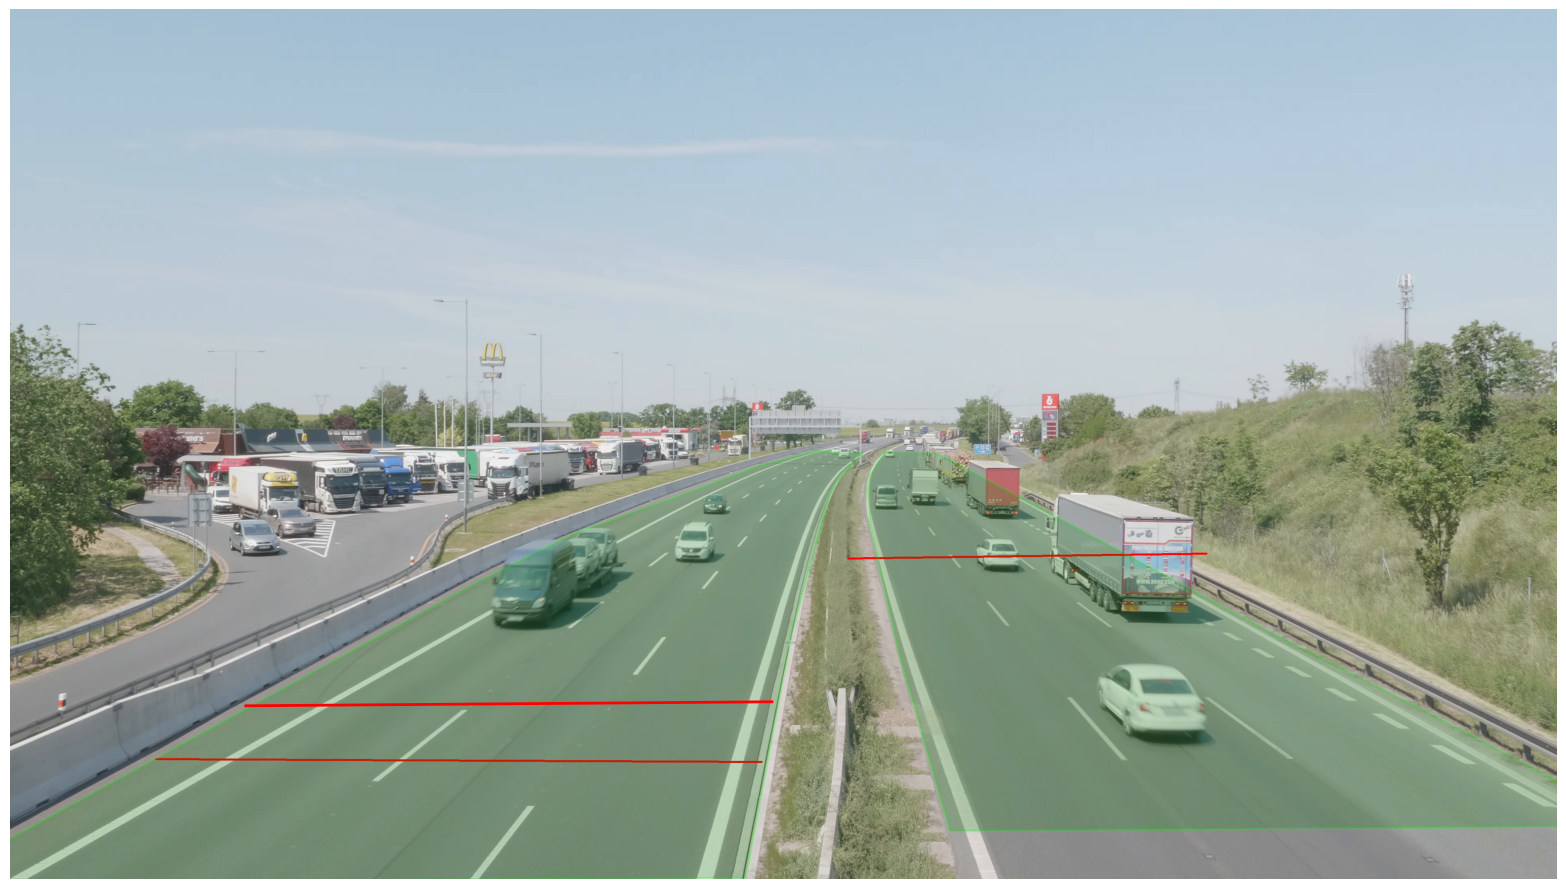

In [19]:
plt.figure(fig2)

left = (582, 1730)
right = (1895, 1720)
new_coords = [left, right]

new_inc_line = Polygon(new_coords, closed=True, 
                       facecolor='red', edgecolor='red', 
                       linewidth=2)

ax2.add_patch(new_inc_line)
plt.show()

In [20]:
# model.predictor = None
model = YOLO("yolov8m.pt")
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")

with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f) 

clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
dir_labels = incoming["directions"]  # Similar for both incoming and outgoing
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]

source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))

roi_incoming = left_roi_points
roi_outgoing = right_roi_points

counter1 = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels)
counter2 = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels)
counters = (counter1, counter2)

output_name = "../outputs/output_count_dev_overhead_medium_congest_01_incline_adj.mp4"
logger2 = process_clip(cap1, model, output_name, counters, log_frames=True)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 281.2s
FPS: 10.2


In [21]:
log2 = logger2.to_dataframe()
print(f"No. of records: {log2.shape[0]}")

pos2 = log2.loc[log2["incoming"] == "positive"]

summary2 = pos2.groupby("track_id").agg(
    count=("frame_n", "size"),
    first_frm=("frame_n", "min"),
    last_frm=("frame_n", "max"),
    span=("frame_n", lambda x: x.max() - x.min()  + 1),
).reset_index()

summary2["contiguous"] = summary2["count"] == summary2["span"]

summary2.sort_values("count").head(10)

No. of records: 43271


,track_id,count,first_frm,last_frm,span,contiguous
70,1278.0,1,2268,2268,1,True
78,1483.0,6,2701,2706,6,True
68,1240.0,7,2259,2265,7,True
12,160.0,8,318,325,8,True
65,1171.0,9,2097,2105,9,True
59,1105.0,9,2040,2048,9,True
83,1559.0,9,2871,2879,9,True
71,1280.0,9,2344,2352,9,True
69,1276.0,10,2321,2330,10,True
79,1496.0,10,2752,2761,10,True


**Observations (After Moving the Incoming Line):**

See the output video [here](https://youtu.be/XLJ-tOKstag).

- The log retains 43,271 records (similar to previous run), one per detection per frame.
- ID 1278 has a span of 1 frame. It’s the same fragment from the earlier check (new ID the ID 1240 van picked up just before leaving, excluded from M).
- ID 1483, the genuine fast car, now holds the positive side for 6 frames (previously 4).
- ID 1240 now holds it for 7 frames (previously 4) before dropping out.
- Moving the line raised the lowest genuine post-crossing count from 4 to 6.

**Final Values:**

M = 6 (ceiling, set by ID 1483).
N = 5 (satisfies N < M, with one frame to spare).

**Notes:**

- With N = 5, the one-frame fragment (ID 1278) can no longer commit a count.
- The van was already counted as ID 1240, so this also guards against a duplicate count from the fragment.
- N was measured for this clip only. N is set per line, so it gets rechecked on each remaining dev clip.

Next, we will determine how many frames ID 928 spent on the wrong side of the outgoing line during the occlusion (floor). As a recap, this is the only occlusion scenario that caused an issue, where it was pushed across by its shrinking box, disappeared, then reappeared back on its original side.

In [23]:
t = log2[log2["track_id"] == 928.0].sort_values(by="frame_n").copy()
t["gap"] = t["frame_n"].diff()
t[t["gap"] > 1]

,frame_n,track_id,box (xyxy),box area,anchor (xy),incoming,outgoing,gap
29710,1891,928.0,"[2610.847412109375, 1197.98046875, 3038.699218...",142105.295169,"(2824.7733154296875, 1530.1171875)",N/A,positive,11.0
31734,2050,928.0,"[2481.798828125, 1148.305908203125, 2723.77392...",54923.709706,"(2602.786376953125, 1375.2867431640625)",N/A,negative,22.0
34813,2275,928.0,"[2416.370849609375, 1124.0609130859375, 2573.4...",26687.668610,"(2494.891845703125, 1294.0006103515625)",N/A,negative,4.0
34862,2279,928.0,"[2413.889404296875, 1123.57177734375, 2572.786...",27136.881571,"(2493.338134765625, 1294.3541259765625)",N/A,negative,3.0
34898,2282,928.0,"[2414.99609375, 1125.1083984375, 2573.47705078...",26941.646620,"(2494.236572265625, 1295.107666015625)",N/A,negative,3.0
34965,2287,928.0,"[2413.790283203125, 1125.25146484375, 2572.294...",26945.741457,"(2493.042236328125, 1295.251953125)",N/A,negative,4.0
35007,2290,928.0,"[2411.945556640625, 1122.7894287109375, 2573.2...",28072.839602,"(2492.5892333984375, 1296.84423828125)",N/A,negative,2.0
35220,2309,928.0,"[2410.955078125, 1125.1768798828125, 2570.6389...",27573.083130,"(2490.7969970703125, 1297.849853515625)",N/A,negative,19.0
35257,2312,928.0,"[2412.12890625, 1126.379638671875, 2570.767822...",27199.370279,"(2491.4483642578125, 1297.834228515625)",N/A,negative,3.0
35281,2314,928.0,"[2412.189453125, 1123.5078125, 2572.7927246093...",28035.386998,"(2492.4910888671875, 1298.07080078125)",N/A,negative,2.0


**Observations:**

- This table shows the exact frames everytime the truck (ID 928) reappeared before being occluded or dropping out.
- The truck vanished for 21 frames (2029 to 2049) and came back at frame 2050, which is around 1:24 in the clip. That’s the occlusion by the passing truck.
- A 21-frame disappearance is far longer than N = 5, so the occlusion itself is well outside what hysteresis is meant to cover.
- There’s an earlier 10-frame dropout until frame 1891, but the truck was still below the line at that point, so it did no harm.
- From frame 2275 onward there are several other dropouts that occurred after the truck crossed the line.

**Notes:** 

Model inference is the slow part of our pipeline. From here on, we run the model only once and save each frame’s `tracked_detections` to a list (or a pickle file). Every test after that will be a replay of the same loop without model inference:

1. Read the clip again
2. Hand each frame its saved detections
3. Update a fresh set of counters
4. Write the annotated video.

No inference is involved, so each replay takes far less time than a full run. This is doable because, as we saw earlier, repeated inference runs produce identical results, down to the track IDs. Even if they didn’t, the saved detections can act as a fixed input. Every test replays the exact same tracks, so any change in the counts can only come from the counting logic or setting we changed, and not from variation in the model or tracker between runs.

**For this test, the sequence will be:**

1. Run the model once, save the detections, and replay them through the current counter. This should reproduce the results of the previous runs. If it does, the replay is reliable.
2. Apply hysteresis, replay, and check the results.
3. Add box-change rejection on top, replay, and check the results.

### **7.2 Run the Model Once, Save Tracked Detections, then Compare with Previous Results**

In [24]:
import pickle

def run_and_save_detections(cap, model, save_path, track_file="bytetrack.yaml"):
    """Run tracking on the whole clip once while storing each frame's detections."""
    saved_detections = []

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret: break

        saved_detections.append(track_vehicles(frame, model,
                                               agnos_nms=True,
                                               track_file=track_file))
    cap.release()

    with open(save_path, "wb") as f:
        pickle.dump(saved_detections, f)

    print(f"Saved {len(saved_detections)} frames to {save_path}")
    return saved_detections

In [25]:
# Run once then save
model = YOLO("yolov8m.pt")   # fresh model so track IDs start from scratch
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
track_file = "../config/bytetrack_w_buffer60.yaml"

saved_detections = run_and_save_detections(
    cap1, model, "../outputs/dets_dev_overhead_medium_congest_01.pkl",
    track_file=track_file)

Saved 2880 frames to /kaggle/working/dets_dev_overhead_medium_congest_01.pkl


In [2]:
def draw_annotations(frame, tracked_detections, counters):
    """
    Draw the counting lines, the detection boxes with their labels, and
    the count overlay on a frame. The frame is modified in place.
    Originally integrated within the process_clips function.
    """

    # Draw the counting lines
    for counter in counters:
        cv2.line(frame, counter.line[0], counter.line[1], (0, 0, 255), 3)

    # Draw the detected boxes with ID, class, and current signs
    for detection in tracked_detections:
        x1, y1, x2, y2 = [int(v) for v in detection["box"]]
        track_id = detection["track_id"]
        cls_id = int(detection["cls_id"])
        color = BOX_COLORS[cls_id]
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 6)

        signs_lst = [f"{counter.line_id[0:3]}:"
                     f"{ {'positive': '+', 'negative': '-'}.get(counter.track_sides.get(track_id), 'N/A') }"
                     for counter in counters]
        signs_str = ", ".join(signs_lst)

        label = (f"ID:{int(track_id)}, "
                 f"{CLASS_MAP[cls_id]}, "
                 f"{signs_str}")

        (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        top = max(y1 - baseline - th - 8, 0)

        cv2.rectangle(frame, (x1, top), (x1 + tw + 8, top + th + baseline + 8), color, -1)
        cv2.putText(frame, label,
                    (x1 + 4, top + th + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 2)

    # Draw the counting overlay to show counts for each line crossing
    for row, counter in enumerate(counters):
        total_count = sum(counter.counts.values())
        txt_total = f"{counter.line_id} total: {total_count}"
        positive_lbl = counter.dir_labels['positive']
        negative_lbl = counter.dir_labels['negative']
        txt_positive = f"positive: {counter.counts[positive_lbl]}"
        txt_negative = f"negative: {counter.counts[negative_lbl]}"
        cv2.putText(frame,
                    txt_total + ", " + txt_positive + ", " + txt_negative,
                    (40, 120 + row * 50),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.2, (255, 0, 0), 2)

In [3]:
def process_clip(cap, fname, model, counters, log_frames=False, saved_dets=None):
    """
    Run tracking + counting over a clip, write an annotated video, and
    optionally return a per-frame, per-detection log. Passed counters are 
    updated in place so we can retrieve their data for logging.
    """

    # Capture and display essential clip information
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) 
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  
    print(f"(W,H): ({w},{h})")
    print(f"fps: {fps}")
    print(f"Total frames: {total_frames}")   

    start = time.time() 
    frame_ctr = 0

    # For counting the total unique IDs that appeared across all frames
    unique_ids = set()   

    out = cv2.VideoWriter(fname,
                          cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))

    if log_frames:
        logger = FrameLogger(counters)

    while cap.isOpened():
        ret, frame = cap.read() 
        if not ret: break

        # Retrieve previously stored detections or generate new ones
        if saved_dets is not None:
            tracked_detections = saved_dets[frame_ctr]
        else:
            tracked_detections = track_vehicles(frame, 
                                                model, 
                                                agnos_nms=True, 
                                                track_file=track_file)

        # Capture unique IDs
        unique_ids.update([d["track_id"] for d in tracked_detections])

        # Update counter states for all LineCrossingCounter objects
        for counter in counters:
            counter.update(tracked_detections, frame_ctr)

        # Log the current frame's information 
        if log_frames:
            for detection in tracked_detections:
                logger.log(frame_ctr, detection)

        # Draw lines, boxes, labels, and counts, then write the frame
        draw_annotations(frame, tracked_detections, counters)
        out.write(frame)
        frame_ctr += 1

        if frame_ctr % 200 == 0: 
            print(f"{frame_ctr}/{total_frames} processed")

    elapsed = time.time() - start
    cap.release()
    out.release()

    print(f"Total unique IDs: {len(unique_ids)}")
    print(f"Duration: {elapsed:.1f}s")
    print(f"FPS: {frame_ctr/elapsed:.1f}")

    if log_frames: return logger

In [28]:
# Load the saved tracked detections
with open("../outputs/dets_dev_overhead_medium_congest_01.pkl", "rb") as f:
    saved_detections = pickle.load(f)

# Load the config file 
with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f)

# Retrieve line configurations
clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
dir_labels = incoming["directions"]  # Similar for both incoming and outgoing
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]

# Create counter objects
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))
roi_incoming = left_roi_points
roi_outgoing = right_roi_points
counter1_new = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels)
counter2_new = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels)
counters = (counter1_new, counter2_new)

logger3 = process_clip(cap=cap1, 
                       fname="output_count_dev_overhead_medium_congest_01_noinfer.mp4", 
                       model=None,
                       counters=counters, 
                       log_frames=True, 
                       saved_dets=saved_detections)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 187.1s
FPS: 15.4


In [29]:
# Check if the newest results are similar to the previous (with adjusted incoming line)
for prev, new in zip((counter1, counter2), (counter1_new, counter2_new)):
    print(new.line_id, prev.counts == new.counts, prev.events == new.events)

incoming True True
outgoing True True


**Takeaway:** We got our expected result. Both new and previous lines produced the same counts and the same events, similar to a full inference run but without one. 

### **7.3 Implement Hysteresis (Temporal) at N=5 then Check Results**

Until now, the counter treated every side flip as a crossing the moment it happened. With temporal hysteresis, a flip has to hold for N consecutive frame sightings before it counts. Our value for this clip is `N = 5`.

**How it Works:**

The counter now keeps two state per track:

1. **Confirmed side:** the side we trust the vehicle to be on (`track_sides`).
2. **Pending flip:** a crossing that is waiting to be confirmed. When a vehicle shows up on the other side of the line, we don’t count it yet. We note which side it moved to, the frame where that first happened, and how many frames in a row it has stayed there.

**For each detection, One of Three Things Happens:**

1. **The vehicle is new.** We haven’t seen this track before, so there’s nothing to compare against. Its current side becomes its confirmed side.
2. **The vehicle is still on its confirmed side.** Nothing has changed. If a flip was waiting to be confirmed, we cancel it, because the vehicle has come back. This is what happens with stationary box jitter, where it flickers pass the line for a frame or two and then returns.
3. **The vehicle is on the other side.** We add one to its pending count. Once it has stayed on the other side for N frames in a row, we accept the crossing. The other side becomes its new confirmed side, and the crossing is counted as long as the cooldown allows it.

**Which Frame do We Record?**

There are two candidate frames for the event:

- **The crossing frame:** the first frame the vehicle appeared on the new side.
- **The commit frame:** the frame where the count reached N.

We record the crossing frame. The event’s `frame_number` and `timestamp` describe when the vehicle crossed, and that should not change everytime we tune N. For example, N = 5, a vehicle that first appears on the new side at frame 100 is committed at frame 104 (its fifth sighting), and the event is logged with frame 100. The cooldown is measured from the recorded crossing frame as well, so both use the same starting point.

In [4]:
def in_roi(roi, anchor_point):
    """Return True if anchor_point lies inside or on the edge of the polygon roi."""
    polygon = np.array(roi, dtype=np.int32)
    return cv2.pointPolygonTest(polygon, anchor_point, False) >= 0
    

# Modify LineCrossingCounter to accomodate a hysteresis mechanism
class LineCrossingCounter:

    def __init__(self, source, fps, line_id, 
                 line, roi, dir_labels, cooldown=30,
                 hyst_n=5):
        
        self.source = source
        self.fps = fps
        self.line_id = line_id
        self.line = line
        self.roi = roi
        self.dir_labels = dir_labels
        self.cooldown = cooldown
        self.last_crossed = {}
        self.tentative_crossed = {}
        self.track_sides = {}
        self.hyst_n = hyst_n

        self.counts = {self.dir_labels["positive"]:0, 
                       self.dir_labels["negative"]:0}

        self.events = []

    def update(self, tracked_detections, frame_number):

        for detection in tracked_detections:

            box = detection["box"]
            x_anchor = (box[0] + box[2]) /2
            y_anchor = box[3]

            # Check first if the anchor point lies within the roi or along its edges
            # If it does, proceed with the rest of the sequence, else skip the 
            # anchor point entirely from being recorded and counted relative to this line
            if not in_roi(self.roi, (x_anchor, y_anchor)):
                continue

            x1, x2 = self.line[0][0], self.line[1][0]
            y1, y2 = self.line[0][1], self.line[1][1]
            cross_product = (x2 - x1) * (y_anchor - y1) - (y2 - y1) * (x_anchor - x1)

            sign = "positive" if cross_product > 0 else "negative"
            track_id = detection["track_id"]

            # The track is new so its current side 
            # immediately becomes its confirmed side
            if track_id not in self.track_sides:
                self.track_sides[track_id] = sign
                continue

            # The track is still on its confirmed side 
            # so a pending flip is cancelled
            if sign == self.track_sides[track_id]:
                self.tentative_crossed.pop(track_id, None)
                continue

            # The track is on the other side 
            # Start or continue a pending flip
            if track_id not in self.tentative_crossed:
                self.tentative_crossed[track_id] = {"flip_frame": frame_number, 
                                                    "count": 0}

            # Add 1 to count for one more sighting on the other side
            self.tentative_crossed[track_id]["count"] += 1

            # If number of frames remained on the new side is 
            # less than hyst_n, wait for the next frame
            if self.tentative_crossed[track_id]["count"] < self.hyst_n:
                continue 

            # The flip held for hyst_n frames so it is committed
            flip_frame = self.tentative_crossed.pop(track_id)["flip_frame"]
            self.track_sides[track_id] = sign

            # Skip the count if this track already crossed 
            # within the last `cooldown` frames
            if track_id in self.last_crossed:
                if flip_frame - self.last_crossed[track_id] <= self.cooldown:
                    continue

            self.last_crossed[track_id] = flip_frame
            self.counts[self.dir_labels[sign]] += 1

            # Build the event log and append to the event list
            event = {
                "source_video": self.source,
                "line_id": self.line_id,
                "vehicle_id": track_id, 
                "frame_number": flip_frame,
                "timestamp": flip_frame / self.fps,
                "direction": self.dir_labels[sign],
                "class": CLASS_MAP[detection["cls_id"]]}

            self.events.append(event)

**Note**: The variables and constants *below* are taken from previous cells. They are for the current clip `dev_overhead_medium_congest_01.mp4` and repeated here for reference. The `FrameLogger` class has been modified and now has a `.get_span` method for producing a derived DataFrame with the `span` column.

In [5]:
left_roi_points = [(-200, 2170),    # bottom-left (lower bound)
                   (1155, 1426),  # left edge (first bend)
                   (1399, 1303),  # left edge (2nd bend)
                   (1640, 1217),  # left edge (3rd bend)
                   (1860, 1134),  # left edge (4th)
                   (2005, 1097),  # top-left (upper bound)
                   (2117, 1104),  # top-right (upper bound)
                   (2053, 1174),  # right edge bend 3
                   (2034, 1213),  # right edge bend 2
                   (1940, 1552),  # right edge bend 1
                   (1826, 2158)]  # bottom-right (lower bound)

right_roi_points = [(2334, 2041),  # bottom-left (lower bound)
                    (2208, 1603),  # left bend
                    (2134, 1272),  # left bend
                    (2129, 1196),  # left bend
                    (2134, 1159),  # left bend
                    (2172, 1100),  # top-left (upper bound)
                    (2300, 1102),  # top-right (upper bound)
                    (2585, 1254),  # right edge bend
                    (3120, 1542),  # right edge bend
                    (3536, 1754),  # right edge bend
                    (4050, 2028)]  # bottom-right (lower bound)


CLASS_MAP = {2:"car", 3:"motorcycle", 5:"bus", 7:"truck"}

BOX_COLORS = {
    2: (255, 255, 255),  # car - white
    3: (255, 200, 100),  # motorcycle - light blue
    5: (203, 192, 255),  # bus - pink
    7: (0, 255, 255)}    # truck - yellow

track_file = "../config/bytetrack_w_buffer60.yaml"


class FrameLogger:
    """
    Accumulates per-frame records into a DataFrame for later
    analysis. One row per detection per frame.
    """
    def __init__(self, counters):
        self.container = []
        self.counters = counters
        self.sign_cols = [c.line_id for c in counters]   
        
    # Append one row corresponding to a single detection in the current frame
    def log(self, frame_n, tracked_detection):
        track_id = tracked_detection["track_id"]
        box = tracked_detection["box"]        
        area = (box[2] - box[0]) * (box[3] - box[1])
        anchor = (box[0] + box[2]) /2, box[3]
                             
        signs = []
        for counter in self.counters:
            sign = counter.track_sides.get(track_id)
            signs.append(sign if sign else "N/A")
        
        self.container.append([frame_n,
                               track_id,
                               box,
                               area,
                               anchor,
                               *signs])
        
    # Return all logged rows as a DataFrame
    def to_dataframe(self):
        columns = ["frame_n",
                   "track_id",
                   "box (xyxy)",
                   "box area",
                   "anchor (xy)",
                   *self.sign_cols]
        
        return pd.DataFrame(self.container, columns=columns)


    def get_span(self, line_id):
        log_df = self.to_dataframe()
        print(f"No. of records: {log_df.shape[0]}")
        pos = log_df.loc[log_df[line_id] == "positive"]

        summary = pos.groupby("track_id").agg(
            count=("frame_n", "size"),
            first_frm=("frame_n", "min"),
            last_frm=("frame_n", "max"),
            span=("frame_n", lambda x: x.max() - x.min()  + 1),
        ).reset_index()

        summary["contiguous"] = summary["count"] == summary["span"]
        return summary.sort_values("count")

In [6]:
# Load the saved tracked detections
with open("../outputs/dets_dev_overhead_medium_congest_01.pkl", "rb") as f:
    saved_detections = pickle.load(f)

# Load the config file 
with open("../config/counting_lines.yaml") as f:
    config = yaml.safe_load(f)

# Retrieve line configurations
clip_config = config["dev_overhead_medium_congest_01.mp4"]
incoming = clip_config["incoming"]
in_coords = incoming["coords"]
outgoing = clip_config["outgoing"]
out_coords = outgoing["coords"]
dir_labels = outgoing["directions"]  

# Create counter objects
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
source = "dev_overhead_medium_congest_01.mp4"
fps = round(cap1.get(cv2.CAP_PROP_FPS))
roi_incoming = left_roi_points
roi_outgoing = right_roi_points
counter_inc = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels, hyst_n=5)
counter_out = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels, hyst_n=5)
counters = (counter_inc, counter_out)

logger4 = process_clip(cap=cap1, 
                       fname="output_count_dev_overhead_medium_congest_01_whystn.mp4", 
                       model=None,
                       counters=counters, 
                       log_frames=True, 
                       saved_dets=saved_detections)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 225.9s
FPS: 12.7


In [7]:
print(f"Incoming Line Counts: {counter_inc.counts}")
print(f"Outgoing Line Counts: {counter_out.counts}")
logger4.get_span("incoming")

Incoming Line Counts: {'B --> A': 83, 'A --> B': 0}
Outgoing Line Counts: {'B --> A': 0, 'A --> B': 69}
No. of records: 43271


,track_id,count,first_frm,last_frm,span,contiguous
70,1278.0,1,2268,2268,1,True
78,1483.0,2,2705,2706,2,True
68,1240.0,3,2263,2265,3,True
12,160.0,4,322,325,4,True
65,1171.0,5,2101,2105,5,True
...,...,...,...,...,...,...
77,1465.0,21,2800,2822,23,False
49,841.0,23,1497,1519,23,True
32,587.0,23,1042,1064,23,True
8,77.0,24,369,392,24,True


#### **Observations**

See output video [here](https://youtu.be/uCESp3f6yk8).

**INCOMING LANE:**

- 81 crossings by hand, 83 by the system. No change from the previous run.
- The two extra counts still come from the van towing a trailer with two cars.
- Hysteresis can’t help there, since those are separate boxes that each cross the line properly.

**OUTGOING LANE:**

- 71 crossings by hand, 69 by the system.
- One of the two missed counts is the motorcycle at around 0:00:23 (same as before).
  - The detector never picked it up, so the counter never had anything to count.
  - That’s a detection miss, not a counting error. The *most the counting logic could have reached on this lane is 70*.
- The other missed count is a van (ID 410 at 0:00:25).
  - It crossed the line, but its detection dropped out before it had been seen 5 times on the other side.
  - For this reason, the crossing was never committed.
  - This is the cost of hysteresis, and it’s a new error.
- The stationary truck (ID 928) issue has been fixed.
  - The passing truck still shrunk its box causing it to cross the line early, though it was not counted immediately with `hyst_n=5`
  - However, the box disappeared before reaching 5 sightings, so it was not counted.
  - When it came back on its original side, the pending crossing was cancelled. Its real crossing later was counted once.
- There are no positive (B --> A) counts in this run, so the wrong-direction error is gone.

**COMPARED WITH THE PREVIOUS RUN:** 

- On paper the previous run looks better because 72 against 71 is off by one, and 69 is off by two.
- But the previous total was close for the wrong reasons.
  - The truck’s extra count made up for the missed motorcycle
  - A wrong-direction count was also recorded on top of that.
  - Three errors happened to nearly cancel out.
- In this run, every counted event is a real vehicle that crossed in the right direction.
- The only errors are two misses, and looking at the output video, we know the cause of each.
- A total that is slightly further off but is made up of correct events is the more trustworthy result.

**WHAT’S NEXT:** We only measured M for the incoming line. ID 410 at 0:00:25 shows that the outgoing line’s M should be below 5, so `hyst_n=5` might be too strict there. Our options are to either move the outgoing line closer to the camera so that ID 410 is committed before it drops out OR lower hyst_n for that line, then replay. For the next run, we **simply lower `hyst_n` from 5 to 4.

In [8]:
cap1 = cv2.VideoCapture("../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
counter_inc = LineCrossingCounter(source, fps, "incoming", in_coords, roi_incoming, dir_labels, hyst_n=5)
counter_out = LineCrossingCounter(source, fps, "outgoing", out_coords, roi_outgoing, dir_labels, hyst_n=4)
counters = (counter_inc, counter_out)

logger5 = process_clip(cap=cap1, 
                       fname="output_count_dev_overhead_medium_congest_01_lower_outhyst.mp4", 
                       model=None,
                       counters=counters, 
                       log_frames=True, 
                       saved_dets=saved_detections)

(W,H): (3840,2160)
fps: 24.000072000216
Total frames: 3000
200/3000 processed
400/3000 processed
600/3000 processed
800/3000 processed
1000/3000 processed
1200/3000 processed
1400/3000 processed
1600/3000 processed
1800/3000 processed
2000/3000 processed
2200/3000 processed
2400/3000 processed
2600/3000 processed
2800/3000 processed
Total unique IDs: 312
Duration: 222.8s
FPS: 12.9


In [12]:
print(f"Incoming Line Counts: {counter_inc.counts}")
print(f"Outgoing Line Counts: {counter_out.counts}")
logger5.get_span("incoming")

Incoming Line Counts: {'B --> A': 83, 'A --> B': 0}
Outgoing Line Counts: {'B --> A': 0, 'A --> B': 70}
No. of records: 43271


,track_id,count,first_frm,last_frm,span,contiguous
70,1278.0,1,2268,2268,1,True
78,1483.0,2,2705,2706,2,True
68,1240.0,3,2263,2265,3,True
12,160.0,4,322,325,4,True
65,1171.0,5,2101,2105,5,True
...,...,...,...,...,...,...
77,1465.0,21,2800,2822,23,False
49,841.0,23,1497,1519,23,True
32,587.0,23,1042,1064,23,True
8,77.0,24,369,392,24,True


#### **Final Result for `dev_overhead_medium_congest_01`**

| **Line** | **By Hand** | **System** | **Net Error** |
| --- | --- | --- | --- | 
| **Incoming** | 81 | 83 | +2 (≈2.5%) |
| **Outgoing** | 71 | 70 | −1 (≈1.4%) |

Both lines are within the 5% net count target. See the ouput video [here](https://youtu.be/CL7M5DTUkfQ).

#### **Why 83 (incoming) and 70 (outgoing) are the Best Counts for this Clip:**

- **Incoming, +2:** a van that tows two cars in a trailer is detected as separate boxes, and each one crosses the line properly. The counting logic works as intended. The extra counts come from how the detector that articulated vehicle.

- **Outgoing, −1:** the motorcycle at 0:00:23 is never detected, so the counter has nothing to count.

Neither error can be fixed in the counting logic. Both would need a change/modified detector.

#### **What Got us Here:**

- Region-gated counting removed the cross-lane counts.
- Applying temporal hysteresis removed the occluded truck’s double count and wrong-direction count (ID 928).
- Decrecovered the van that hysteresis had dropped.
- Every counted event is now a real crossing in the right direction.

#### **Final Settings**

- `track_buffer=60`
- `agnostic_nms=True`
- `cooldown=30`
- Incoming `hyst_n=5` (M = 6)
- Outgoing `hyst_n=4` (M = 5)

**Not needed for now (at least not for this clip):** Box-change rejection. We have observed that hysteresis handled the occlusion case on its, so we’re holding it back unless another clip needs it.

**Next:** A new notebook covering the remaining three dev clips, where each line’s M and hyst_n get checked again.